In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.decomposition import PCA
from sklearn.manifold import LocallyLinearEmbedding
splits = {'train': 'Data/train-00000-of-00001.parquet', 'test': 'Data/test-00000-of-00001.parquet'}
df_train = pd.read_parquet(splits["train"])
df_test = pd.read_parquet( splits["test"])

Ytrain= df_train.label
Ytest= df_test.label
text_train = df_train.text
text_test= df_test.text
def clean(text):
    nonwords=["<br />"]
    for remove in nonwords:
        text = text.replace(remove, " ")
    text= text.lower()
    text = re.sub(r'[^A-Za-z\s]', ' ', text)
    return text

cleanedTrain= []
for text in text_train:
    cleanedTrain.append(clean(text).split())
cleanedTest= []
for text in text_test:
    cleanedTest.append(clean(text).split())

print(cleanedTrain[0])
n= len(cleanedTrain)

['i', 'rented', 'i', 'am', 'curious', 'yellow', 'from', 'my', 'video', 'store', 'because', 'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first', 'released', 'in', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized', 'by', 'u', 's', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore', 'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to', 'see', 'this', 'for', 'myself', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young', 'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything', 'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her', 'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average', 'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam', 'war', 'and', 'race', 'issues', 'in', 'the', 'united', 'states', 'i

In [3]:
print("The share of positive sentence in the raining set is ", np.mean(Ytrain), " with ", n, " datapoints and for the test set", np.mean(Ytest),"from", len(Ytest), "datapoints.")

The share of positive sentence in the raining set is  0.5  with  25000  datapoints and for the test set 0.5 from 25000 datapoints.


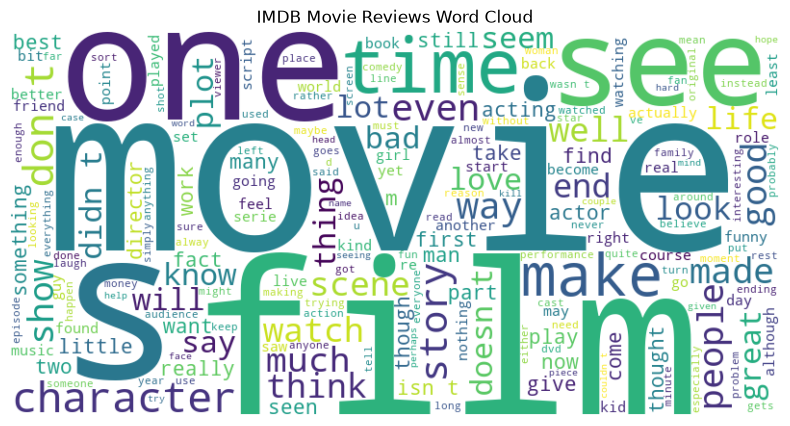

In [4]:
from wordcloud import WordCloud
entiretext=""
for text in text_train:
    entiretext += " "+clean(text)
entire_train_text=entiretext# encoding only on the training set part
for text in text_test:
    entiretext += " "+clean(text)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(entiretext)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  
plt.title("IMDB Movie Reviews Word Cloud")
plt.show()

##  Tokenization and Onehotencoding

In [5]:
tokens={}

occurences=[]
for word in entire_train_text.split():
    if word in tokens:
        occurences[tokens[word]]+=1
    else:
        tokens[word]=len(occurences)
        
        occurences.append(1)


reducedtoken={}
words=[]
minoccurence=10
for word in tokens:
    i = tokens[word]
    if occurences[i]>minoccurence:
        reducedtoken[word]= len(reducedtoken)
        words.append(word)
        
tokenamount=len(reducedtoken)


print("Out of ", len(tokens), "words only ",tokenamount, "occur more than ", minoccurence, "times in the entire training set.")

onehotTrain = np.zeros([n, tokenamount])
for i in range(n):
    for word in cleanedTrain[i]:
         if word in reducedtoken:# if the word is not occuring enough it will be ignored
            onehotTrain[i,reducedtoken[word]] +=1


onehotTest = np.zeros([n, tokenamount])
for i in range(n):
    for word in cleanedTest[i]:
        if word in reducedtoken:# if the word is not known in the training set it will be ignored
            onehotTest[i,reducedtoken[word]] +=1


Out of  73272 words only  18840 occur more than  10 times in the entire training set.


# Simple Logistic Regression

In [6]:
logistic_classifier = LogisticRegression(max_iter=200)
logistic_classifier.fit(onehotTrain, Ytrain)

/opt/miniconda3/envs/LUT_ADAML/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

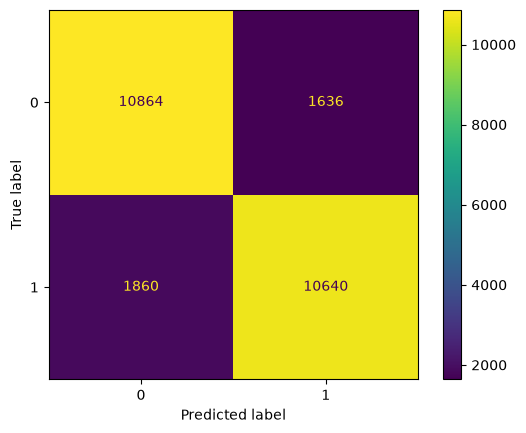

{'Accuracy': 0.86016, 'F1_score': 0.8588957055214724, 'Sensitivity': 0.8512, 'Specificity': 0.86912}


In [7]:
def evaluateModel(predicted, actual):
    confusion_matrix = metrics.confusion_matrix(actual, predicted)
    cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [0, 1])
    cm_display.plot()
    plt.show()
    Accuracy = metrics.accuracy_score(actual, predicted)
    F1_score = metrics.f1_score(actual, predicted)
    Recall = metrics.recall_score(actual, predicted)
    Specificity = metrics.recall_score(actual, predicted, pos_label=0)
    print({"Accuracy":Accuracy,"F1_score":F1_score, "Sensitivity": Recall, "Specificity": Specificity})
y_pred = logistic_classifier.predict(onehotTest)
evaluateModel(y_pred, Ytest)

# Data visualisations 
### PCA 

For the contours the data was transformed into 2-d structure using PCA.


In [8]:
pca = PCA(n_components=2)
X_train = pca.fit_transform(onehotTrain)
X_test = pca.transform(onehotTest)

# pca_logistic_classifier = LogisticRegression(max_iter=200)
# pca_logistic_classifier.fit(X_train, Ytrain)
# pca_y_pred = pca_logistic_classifier.predict(X_test)
# evaluateModel(pca_y_pred, Ytest)

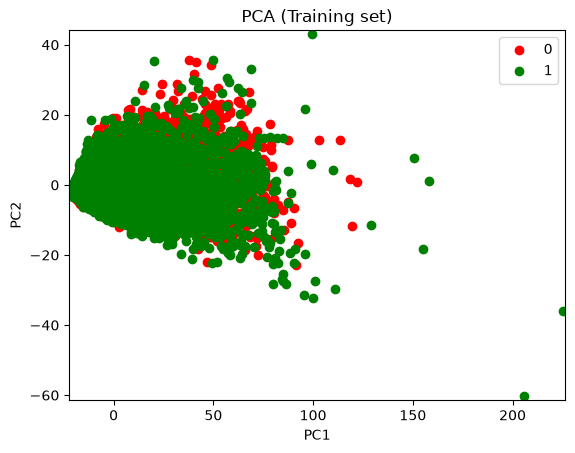

In [9]:
from matplotlib.colors import ListedColormap

X_set, y_set = X_train, Ytrain
X1, X2 = np.meshgrid(np.arange(start=X_set[:, 0].min() - 1,
                               stop=X_set[:, 0].max() + 1, step=0.01),
                     np.arange(start=X_set[:, 1].min() - 1,
                               stop=X_set[:, 1].max() + 1, step=0.01))

# plt.contourf(X1, X2, pca_logistic_classifier.predict(np.array([X1.ravel(),
#                                                   X2.ravel()]).T).reshape(X1.shape), alpha=0.75,
#              cmap=ListedColormap(('yellow', 'white', 'aquamarine')))

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color=ListedColormap(('red', 'green'))(i), label=j)

plt.title('PCA (Training set)')
plt.xlabel('PC1')  # for Xlabel
plt.ylabel('PC2')  # for Ylabel


# show scatter plot
# The loadings cannot be showed as they are to small to be visible

plt.legend()  # to show legend
plt.show() 



## LLE

In [21]:
lle = LocallyLinearEmbedding(n_neighbors=20, n_components=2, n_jobs=-1)
X_reduced = lle.fit_transform(onehotTest)
print("LLE done")

LLE done


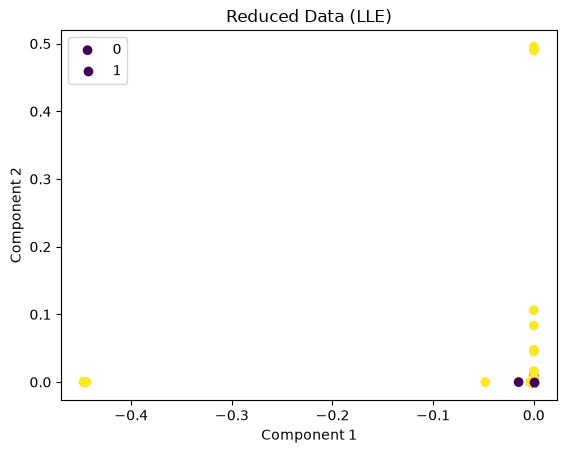

In [29]:
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=Ytest)
plt.scatter(X_reduced[19240, 0], X_reduced[19240, 1], c=0)
plt.title("Reduced Data (LLE)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend([0,1])
plt.show()

## UMAP

In [ ]:
import umap
fit = umap.UMAP()


neigh=[2,3,7]
dist=[0.1, 0.5, 0.8]
for i in range(9):
    neighbors=neigh[i//3]
    distance=dist[i%3]
    print("#Neighbors:", neighbors, "Dist", distance)
    fit = umap.UMAP(
            n_neighbors=neighbors,
            min_dist=distance,
            n_components=2,
        )
    u = fit.fit_transform(X_train)
    plt.subplot(3,3, i+1)
    plt.scatter(u[:12500,0], u[:12500,1], c="red")
    plt.scatter(u[12500:,0], u[12500:,1], c="green")
    plt.title('UMAP embedding')
    plt.legend([0,1])
plt.show()

#Neighbors: 2 Dist 0.1


/opt/miniconda3/envs/LUT_ADAML/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


#Neighbors: 2 Dist 0.5
